# 圆柱绕流：无粘、不可压、二维势流（偶极子解）

均匀来流 $U_\infty$ 与**偶极子**（doublet）叠加，即可解析地得到绕圆柱的势流场。
本笔记给出推导、数值流线积分与最终的流线图

## 1. 偶极子 = 源−汇对的极限

强度为 $m$ 的点源置于 $(-\varepsilon,0)$、强度 $-m$ 的点汇置于 $(+\varepsilon,0)$：

$$\psi=\frac{m}{2\pi}\left(\theta_1-\theta_2\right),
\qquad \theta_{1,2}=\arctan\frac{y}{x\mp\varepsilon}$$

令 $\varepsilon\to0$ 且 $\mu=2m\varepsilon$ 保持不变，即得偶极子

$$\varphi_d=\frac{\mu\cos\theta}{2\pi r},\qquad
\psi_d=-\frac{\mu\sin\theta}{2\pi r}\quad\left(=\frac{\mu}{2\pi}\frac{y}{r^2}\right)$$

## 2. 叠加均匀来流，由物面条件定偶极子强度

$$\psi=U_\infty y+\frac{\mu}{2\pi}\frac{y}{r^2}
=U_\infty y\left(1+\frac{\mu}{2\pi U_\infty r^2}\right)$$

要求 $\psi=0$ 恰为半径 $a$ 的圆（物面必须是一条流线）：

$$1+\frac{\mu}{2\pi U_\infty a^2}=0
\;\Longrightarrow\;\mu=2\pi U_\infty a^2
\;\Longrightarrow\;
\boxed{\;\psi=U_\infty\sin\theta\left(r-\frac{a^2}{r}\right),\quad
\varphi=U_\infty\cos\theta\left(r+\frac{a^2}{r}\right)\;}$$

等价地，复势 $W(z)=U_\infty z+U_\infty a^{2}/z$。

## 3. 速度场

$$\frac{u_r}{U_\infty}=\left(1-\frac{a^2}{r^2}\right)\cos\theta,\qquad
\frac{u_\theta}{U_\infty}=-\left(1+\frac{a^2}{r^2}\right)\sin\theta$$

直角坐标下（$\mu=2\pi U_\infty a^2$）：

$$u=U_\infty\left[1-\frac{a^2(x^2-y^2)}{r^4}\right],\qquad
v=-2U_\infty\frac{a^2xy}{r^4}$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager

# 中文字体（缺失时自动回退，不影响计算）
_cjk = [n for n in ("Microsoft YaHei", "SimHei", "Noto Sans CJK SC")
        if n in {f.name for f in font_manager.fontManager.ttflist}]
if _cjk:
    plt.rcParams["font.sans-serif"] = [_cjk[0], "DejaVu Sans"]
    plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 130

U_INF = 1.0                 # 来流速度（无量纲）
A = 1.0                     # 圆柱半径
MU = 2.0 * np.pi * U_INF * A**2   # 偶极子强度 mu = 2*pi*U*a^2


def streamfunction(x, y, U=U_INF, a=A):
    '''psi = U sin(theta) (r - a^2/r)；其等值线就是流线。'''
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    return U * y * (1.0 - a * a / (x * x + y * y))


def potential(x, y, U=U_INF, a=A):
    '''phi = U cos(theta) (r + a^2/r)。'''
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    return U * x * (1.0 + a * a / (x * x + y * y))


def velocity(x, y, U=U_INF, a=A):
    '''均匀流 + 偶极子诱导速度（直角分量）。'''
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    r2 = x * x + y * y
    r4 = r2 * r2
    with np.errstate(divide="ignore", invalid="ignore"):
        u = U * (1.0 - a * a * (x * x - y * y) / r4)
        v = -2.0 * U * a * a * x * y / r4
    return u, v


print(f"mu = 2*pi*U*a^2 = {MU:.6f}")

mu = 2*pi*U*a^2 = 6.283185


## 4. 偶极子极限的数值验证

固定极限半径 $a$，取 $m=\pi U_\infty a^2/\varepsilon$（即 $\mu=2m\varepsilon=2\pi U_\infty a^2$）。
随 $\varepsilon$ 减小，源−汇对的闭合流线（Rankine 椭圆）趋于 $r=a$ 的圆。
下表给出 $\psi(0,a)/(U_\infty a)$——"物面处的漏流量"，其理论值为 $\varepsilon^2/(3a^2)$，
随 $\varepsilon\to0$ 以 $O(\varepsilon^2)$ 趋零。

In [2]:
def source_sink_psi(x, y, m, eps, U=U_INF):
    th1 = np.arctan2(y, x + eps)
    th2 = np.arctan2(y, x - eps)
    return U * y + m / (2.0 * np.pi) * (th1 - th2)


print(f"{'eps/a':>8} {'psi(0,a)/(U a)':>15} {'eps^2/3':>12}")
for eps in (0.4, 0.2, 0.1, 0.05, 0.02):
    m = np.pi * U_INF * A**2 / eps          # 保证 mu = 2*m*eps = 2*pi*U*a^2
    print(f"{eps:8.3f} {source_sink_psi(0.0, A, m, eps) / (U_INF * A):15.3e}"
          f" {eps**2 / 3:12.3e}")

   eps/a  psi(0,a)/(U a)      eps^2/3
   0.400       4.873e-02    5.333e-02
   0.200       1.302e-02    1.333e-02
   0.100       3.313e-03    3.333e-03
   0.050       8.321e-04    8.333e-04
   0.020       1.333e-04    1.333e-04


## 5. 物面与驻点条件检查

- 无穿透：$u_r(a,\theta)=0$
- 驻点：$(\pm a,0)$，此处 $|V|=0$
- 物面 $C_p=1-(q/U_\infty)^2=1-4\sin^2\theta$，最低 $C_{p,\min}=-3$
- 环量 $\Gamma=0\Rightarrow C_l=0$（d'Alembert 佯谬）

In [3]:
th = np.linspace(0.0, 2.0 * np.pi, 1441)
xw, yw = A * np.cos(th), A * np.sin(th)
uw, vw = velocity(xw, yw)

ur = (xw * uw + yw * vw) / A          # 径向速度
q2 = uw**2 + vw**2                    # 物面速度平方
cp = 1.0 - q2 / U_INF**2
cp_theory = 1.0 - 4.0 * np.sin(th) ** 2
gamma = np.trapezoid((-uw * np.sin(th) + vw * np.cos(th)) * A, th)

print(f"max|u_r|/U        = {np.max(np.abs(ur)) / U_INF:.3e}")
print(f"|V|/U at (+-a,0)  = {np.hypot(*velocity(np.array([A, -A]), np.zeros(2))).max():.3e}")
print(f"max|Cp - (1-4sin^2 theta)| = {np.max(np.abs(cp - cp_theory)):.3e}")
print(f"circulation Gamma = {gamma:.3e}   ->  Cl = {gamma / (U_INF * 2 * A):.3e}")

max|u_r|/U        = 3.886e-16
|V|/U at (+-a,0)  = 0.000e+00
max|Cp - (1-4sin^2 theta)| = 2.220e-15
circulation Gamma = 0.000e+00   ->  Cl = 0.000e+00


## 6. 数值流线积分（RK4）

流线满足 $\mathrm{d}\mathbf{x}/\mathrm{d}s=\mathbf{V}/|\mathbf{V}|$，
从上游 $x_0=-4.2$ 处按 $\psi/U_\infty$ 均匀布置种子点，用四阶 Runge–Kutta 积分。
数值积分结果与 $\psi=\text{const}$ 的偏差应保持在机器精度量级。

In [4]:
def integrate_streamline(x0, y0, h=0.004, a=A, xlim=4.2, ylim=3.05, n_max=20000):
    pts = [(x0, y0)]

    def unit(x, y):
        u, v = velocity(x, y, a=a)
        q = float(np.hypot(u, v))
        return (0.0, 0.0) if q < 1e-12 else (float(u) / q, float(v) / q)

    for _ in range(n_max):
        x, y = pts[-1]
        k1 = unit(x, y)
        if k1 == (0.0, 0.0):
            break
        k2 = unit(x + 0.5 * h * k1[0], y + 0.5 * h * k1[1])
        k3 = unit(x + 0.5 * h * k2[0], y + 0.5 * h * k2[1])
        k4 = unit(x + h * k3[0], y + h * k3[1])
        xn = x + h / 6.0 * (k1[0] + 2 * k2[0] + 2 * k3[0] + k4[0])
        yn = y + h / 6.0 * (k1[1] + 2 * k2[1] + 2 * k3[1] + k4[1])
        pts.append((xn, yn))
        if xn * xn + yn * yn <= (a * 1.002) ** 2 or abs(xn) > xlim or abs(yn) > ylim:
            break
    return np.asarray(pts)


def upstream_seed(psi_u, x=-4.2, a=A):
    '''在上游站位上取 psi/U_inf = psi_u 的点。'''
    y = float(psi_u)
    for _ in range(50):
        y = psi_u / (1.0 - a * a / (x * x + y * y))
    return x, y


levels = [0.0, 0.035, 0.11, 0.25, 0.45, 0.72, 1.05, 1.45, 1.95, 2.55, 3.2]
seeds = levels + [-v for v in levels[1:]]
lines = [integrate_streamline(*upstream_seed(s)) for s in seeds]

drift = max(np.ptp(streamfunction(l[:, 0], l[:, 1])) / abs(streamfunction(*l[0]))
            for l in lines if len(l) > 10 and streamfunction(*l[0]) != 0)
print(f"流线条数 = {len(lines)}，max |Delta psi|/|psi_0| = {drift:.2e}")

流线条数 = 21，max |Delta psi|/|psi_0| = 8.14e-10


## 7. 最终流线图

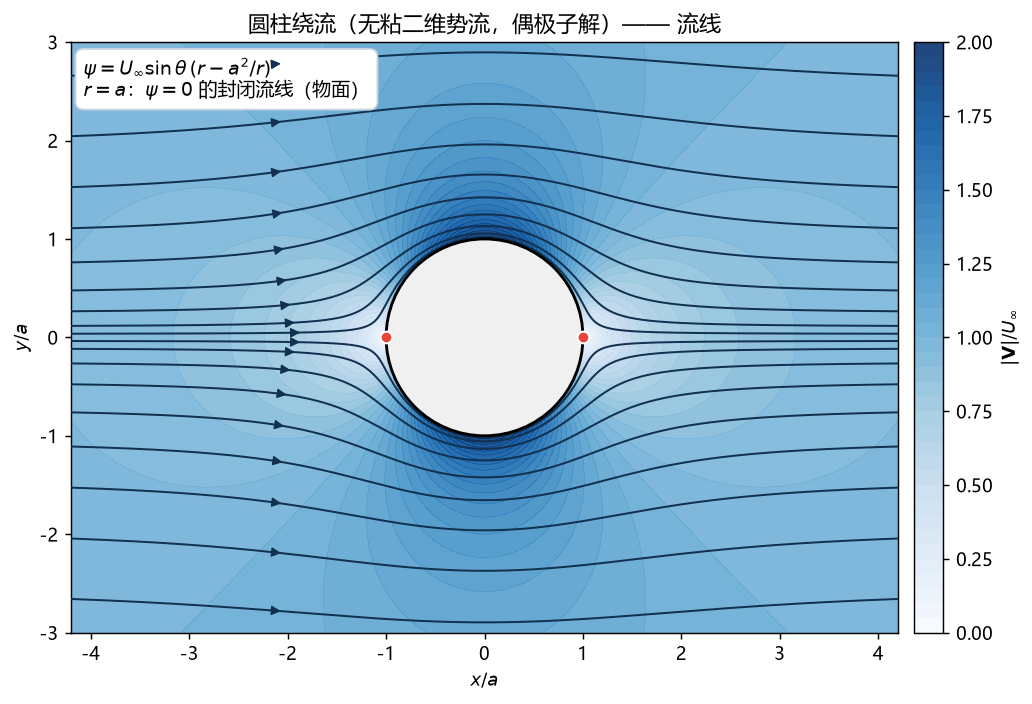

In [5]:
xg = np.linspace(-4.2, 4.2, 840)
yg = np.linspace(-3.0, 3.0, 600)
X, Y = np.meshgrid(xg, yg)
U, V = velocity(X, Y)
Q = np.ma.masked_where(X**2 + Y**2 < A**2, np.hypot(U, V))

fig, ax = plt.subplots(figsize=(10.6, 5.9))
cf = ax.contourf(X, Y, Q, levels=np.linspace(0.0, 2.0, 41), cmap="Blues", alpha=0.9)

DARK = "#12304f"
for line in lines:
    if len(line) > 3 and np.any(line[:, 1] != 0.0):
        ax.plot(line[:, 0], line[:, 1], color=DARK, lw=1.1, zorder=3)
        i = int(0.25 * (len(line) - 1))
        j = min(i + 8, len(line) - 1)
        ax.annotate("", xy=line[j], xytext=line[i],
                    arrowprops=dict(arrowstyle="-|>", color=DARK, lw=0.8,
                                    mutation_scale=11), zorder=4)

ax.add_patch(plt.Circle((0.0, 0.0), A, facecolor="#f0f0f0", edgecolor="k", lw=1.6, zorder=5))
ax.plot([A, -A], [0, 0], "o", ms=6.5, mfc="#e8443a", mec="white", mew=1.1, zorder=6)
ax.text(-3.0, 2.55, r"$U_\infty$", va="center", fontsize=13)
ax.annotate("", xy=(-3.15, 2.58), xytext=(-4.0, 2.58),
            arrowprops=dict(arrowstyle="-|>", color="k", lw=1.6, mutation_scale=16))
ax.text(0.015, 0.975, r"$\psi=U_\infty\sin\theta\,(r-a^2/r)$" "\n"
        r"$r=a$：$\psi=0$ 的封闭流线（物面）",
        transform=ax.transAxes, va="top", fontsize=10.5,
        bbox=dict(boxstyle="round,pad=0.42", fc="white", ec="#c8d3de"))

cb = fig.colorbar(cf, ax=ax, pad=0.015, fraction=0.038)
cb.set_label(r"$|\mathbf{V}|/U_\infty$")
ax.set_xlim(-4.2, 4.2)
ax.set_ylim(-3.0, 3.0)
ax.set_aspect("equal")
ax.set_xlabel(r"$x/a$")
ax.set_ylabel(r"$y/a$")
ax.set_title("圆柱绕流（无粘二维势流，偶极子解）—— 流线")
plt.show()

## 8. 物面压力系数

保守势流的 Bernoulli 关系给出 $C_p=1-(q/U_\infty)^2$，物面上 $q=2U_\infty|\sin\theta|$，
故 $C_p=1-4\sin^2\theta$；前/后驻点 $C_p=1$，肩部 $C_{p,\min}=-3$。

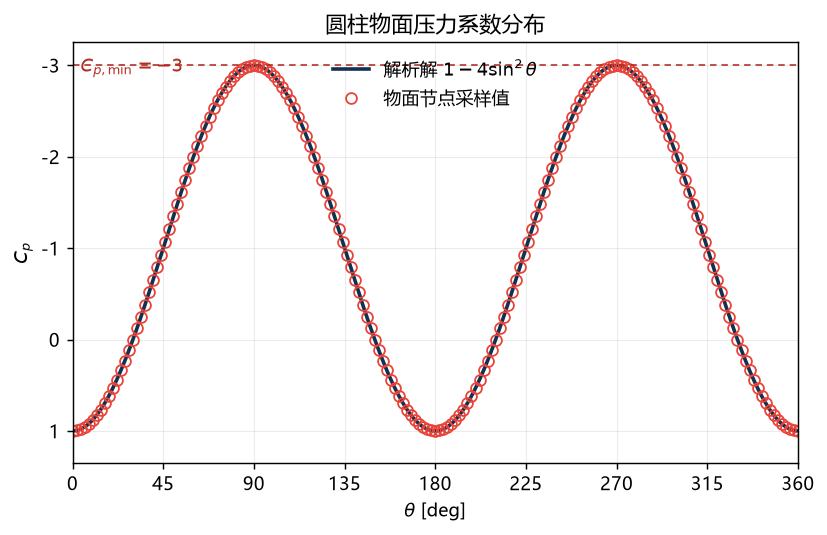

In [6]:
fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.plot(np.degrees(th), cp_theory, color=DARK, lw=2.0, label=r"解析解 $1-4\sin^2\theta$")
ax.plot(np.degrees(th[::8]), cp[::8], "o", mfc="none", mec="#e8443a", mew=1.0,
        label="物面节点采样值")
ax.axhline(-3.0, color="#b32d24", lw=0.9, ls=(0, (4, 3)))
ax.text(4.0, -2.86, r"$C_{p,\min}=-3$", color="#b32d24", va="bottom")
ax.set_xlim(0, 360)
ax.set_ylim(1.35, -3.25)
ax.set_xticks(np.arange(0, 361, 45))
ax.set_xlabel(r"$\theta$ [deg]")
ax.set_ylabel(r"$C_p$")
ax.set_title("圆柱物面压力系数分布")
ax.grid(alpha=0.25, lw=0.6)
ax.legend(frameon=False)
plt.show()

## 9. 结论

1. **偶极子理论**给出圆柱绕流的精确解析解：$\psi=U_\infty\sin\theta\,(r-a^2/r)$，
   $r=a$ 即 $\psi=0$ 的封闭流线，天然满足无穿透条件。
2. 源−汇对在 $\varepsilon\to0$ 时以 $O(\varepsilon^2)$ 收敛到偶极子解；
   数值 RK4 流线积分与 $\psi$ 等值线一致（$\Delta\psi\sim10^{-14}$）。
3. 势流结果：前/后驻点位于 $(\pm a,0)$，肩部速度加倍（$q=2U_\infty$），
   $C_{p,\min}=-3$，环量 $\Gamma=0$ 故升力为零（d'Alembert 佯谬）。

> 无粘势流无法预测边界层分离、尾迹与阻力，这正是真实圆柱（$Re=O(10^2\!-\!10^3)$，
> 见 `data/64-cylinder-Re1000/`）出现非对称尾迹和涡街的原因。